# DepoNav AI — Uçtan Uca Proje

**Ayakkabı Depolarında Mevsimsel Özelliklerle Ürün Bazlı Talep Sınıflandırması ve Exact TSP Rota Optimizasyonu**

**Ders:** Yapay Zekâ Sistem Tasarımı ve Yaşam Döngüsü  
**Veri seti:** Customer_Order, Picking_Wave, Storage_Location  
**Sınıflandırma:** Logistic Regression (baseline), Random Forest, Decision Tree, XGBoost  
**Optimizasyon:** Exact TSP (kanıtlanan optimum), önceden kaydedilmiş rotalar, forklift simülasyonu.

> Ana fikir: Makine öğrenmesi **bir sonraki kayıtlı operasyon gününde bir ürünün sipariş edilme ihtimalini** sınıflandırır. Optimizasyon, **bilinen dalga raflarının** ziyaret sırasını belirler. Bu iki işlem farklı problemleri çözer.

> **Önemli sınırlama:** Tarihler 2023'e aittir. Tek kısmi yıl mevsimselliği kanıtlamaz. Mesafeler yaklaşık koridor modeline aittir; forklift simülasyonu fiziksel araç telemetrisi değildir.

## 1. Paketler ve dosya düzeni

Notebook ile `train_models.py`, `product_demand.py`, `warehouse_core.py`, `app.py`, `data/`, `models/`, `outputs/` aynı klasörde bulunmalıdır. Önceki TSP çıktıları korunur. Pip kurulumu için `requirements.txt` kullanılır.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display, HTML
from product_demand import ROOT, BASE, SEASON, source_matrix, features_for_day, make_training_frame, future_features
from train_models import FEATURES, prepare_data, run as train_four_models, time_cv_splits, slug
print('Proje kökü:',ROOT)
print('sklearn:',sklearn.__version__)
print('Sezon özelliği:',len(SEASON),'Toplam özellik:',len(FEATURES))

Proje kökü: /mnt/data/DepoNav_4_Model_XGBoost_2026_FINAL
sklearn: 1.8.0
Sezon özelliği: 10 Toplam özellik: 32


## 2. Ham veriyi yükle ve kapsamı doğrula

Kaydı olmayan takvim günleri otomatik sıfır sipariş olarak kabul edilmez. `Size (US)` eksikleri ürün talebinin hedefini etkilemediği için rastgele doldurulmaz.

In [2]:
orders=pd.read_csv(ROOT/'data'/'Customer_Order.csv',sep=';')
waves=pd.read_csv(ROOT/'data'/'Picking_Wave.csv',sep=';')
storage=pd.read_csv(ROOT/'data'/'Storage_Location.csv')
for name,df in [('Customer_Order',orders),('Picking_Wave',waves),('Storage_Location',storage)]:
    print(name,'satır × sütun:',df.shape,'toplam eksik:',int(df.isna().sum().sum()))
print('Eksik Size (US):',int(orders['Size (US)'].isna().sum()))
print('Eksik raf adresleri ayrıca optimizasyon kaynağında tutulur; silinmez.')

Customer_Order satır × sütun: (122370, 9) toplam eksik: 16
Picking_Wave satır × sütun: (215192, 6) toplam eksik: 0
Storage_Location satır × sütun: (2292, 5) toplam eksik: 0
Eksik Size (US): 16
Eksik raf adresleri ayrıca optimizasyon kaynağında tutulur; silinmez.


## 3. Hedef değişken: Bir sonraki kayıtlı günde ürün var mı?

Her `(gün, Reference)` gözlemi için hedef **1 = ürün sipariş edilmiş**, **0 = edilmemiş**. Hedef ürün miktarı veya stok tükenmesi değildir. Daha önce hiç sipariş edilmeyen referansların geleceği tahmin edilemez: **cold-start**.

In [3]:
pivot,raw=source_matrix()
frame,coverage=make_training_frame(pivot)
print('Operasyon günü:',len(pivot),'farklı SKU:',len(pivot.columns))
print('Özellik seti:',frame.shape)
print('Hedef pozitif oranı:',round(frame.target.mean(),3))
display(frame[['date','Reference','freq_7','freq_30','month','season_code','target']].head(8))

Operasyon günü: 178 farklı SKU: 208
Özellik seti: (29123, 36)
Hedef pozitif oranı: 0.37


,date,Reference,freq_7,freq_30,month,season_code,target
0,2023-02-16,02MRUH,0.000000,0.266667,2,0,0
1,2023-02-16,05W6TK,1.000000,0.966667,2,0,1
2,2023-02-16,066BOU,0.000000,0.133333,2,0,0
3,2023-02-16,0LNUOV,0.714286,0.900000,2,0,1
4,2023-02-16,0SJH1Z,0.285714,0.300000,2,0,1
5,2023-02-16,122OKQ,0.000000,0.133333,2,0,0
6,2023-02-16,1A6YTA,0.000000,0.166667,2,0,0
7,2023-02-16,1D2ILZ,0.142857,0.133333,2,0,1


## 4. Sadece geçmişten özellik üretimi

Ürün geçmişinin 3, 7, 14, 30, 60 kayıtlı gündeki talep sıklığı; son görülme süresi, miktar özeti, trend gibi davranış özellikleri çıkarılır. Sezon özellikleri: ay, çeyrek, haftanın günü, sinüs/kosinüs tarih dönüşümleri ve **yalnız geçmişte aynı sezonda** gözlenen talep oranı. Referans numarasından bot/terlik türü türetilmez.

In [4]:
print('Davranış özellikleri (BASE):',BASE)
print('Tüm modellerde kullanılan sezon özellikleri (SEASON):',SEASON)
assert set(SEASON).issubset(FEATURES)
i=140
original=features_for_day(pivot,i)
changed=pivot.copy();changed.iloc[i:,:]=9999
pd.testing.assert_frame_equal(original,features_for_day(changed,i))
print('Sızıntı testi başarılı: tahmin günü/sonrası değiştirilse de günün özellikleri değişmiyor.')

Davranış özellikleri (BASE): ['sku_past_days', 'days_since_first', 'days_since_last', 'days_since_prev_operation', 'seen_previous', 'seen_2ago', 'seen_3ago', 'qty_previous', 'historical_rate', 'freq_3', 'freq_7', 'freq_14', 'freq_30', 'freq_60', 'mean_units_7', 'mean_units_14', 'mean_units_30', 'mean_units_60', 'mean_units_when_sold_30', 'max_units_30', 'trend_7_30', 'trend_14_60']
Tüm modellerde kullanılan sezon özellikleri (SEASON): ['month', 'quarter', 'day_of_week', 'day_of_year_sin', 'day_of_year_cos', 'month_sin', 'month_cos', 'season_code', 'season_history_rate', 'season_history_count']
Sızıntı testi başarılı: tahmin günü/sonrası değiştirilse de günün özellikleri değişmiyor.


## 5. Kronolojik eğitim, doğrulama ve bağımsız test

178 kayıtlı günün ilk 30'u geçmiş oluşturmak içindir. Ardından **96 eğitim**, **26 doğrulama**, **26 unseen test** günü kullanılır. Model hiperparametreleri ve eşikleri testte belirlenmez. Gelişen geçmiş pencere (expanding-window) ile **3 fold CV**, yalnız eğitim döneminde yapılır.

In [5]:
pivot,raw,frame,coverage,train,valid,test=prepare_data()
for name,df in [('Eğitim',train),('Doğrulama',valid),('Unseen test',test)]:
    print(name,'gün=',df.day_idx.nunique(),'gözlem=',len(df),'tarih=',df.date.min().date(),'-',df.date.max().date())
print('CV foldları (ilk eğitim günü, son eğitim hariç, ilk CV val, son CV val hariç):')
print(time_cv_splits())
assert train.date.max()<valid.date.min()<test.date.min()

Eğitim gün= 96 gözlem= 18521 tarih= 2023-02-16 - 2023-07-26
Doğrulama gün= 26 gözlem= 5260 tarih= 2023-07-27 - 2023-09-05
Unseen test gün= 26 gözlem= 5342 tarih= 2023-09-06 - 2023-10-19
CV foldları (ilk eğitim günü, son eğitim hariç, ilk CV val, son CV val hariç):
[(30, 66, 66, 86), (30, 86, 86, 106), (30, 106, 106, 126)]


## 6. Dört sınıflandırıcı ve tek bir baseline

1. **Logistic Regression (baseline):** Basit, ölçekleme sonrası doğrusal karar modeli.  
2. **Random Forest:** Ağaç topluluğuyla doğrusal olmayan ilişkiler.  
3. **Decision Tree:** Rastgeleleştirilmiş ağaç topluluğu.  
4. **XGBoost:** Ardışık iyileştiren ağaç modeli.

**Ek referans:** Son 30 kayıtlı gündeki talep sıklığı. Bu bir *beşinci ML modeli değil*, kurala dayalı kontrol.

Tüm modeller **aynı BASE + SEASON özellikleriyle** çalışır. Sezonlu–sezonsuz ayrı model ailesi kullanılmaz.

In [6]:
from train_models import make_model
for model_name in ['Logistic Regression (Baseline)','Random Forest','Decision Tree','XGBoost']:
    print(model_name,':',type(make_model(model_name)).__name__)

Logistic Regression (Baseline) : Pipeline
Random Forest : RandomForestClassifier
Decision Tree : DecisionTreeClassifier
XGBoost : XGBClassifier


## 7. Precision–Recall kararı ve ana ölçüt

**False Negative (FN):** Talep görülecek ürün için hazırlığı kaçırırız.  
**False Positive (FP):** Talep görmeyecek ürün için gereksiz hazırlık yaparız.

Depo hazırlık senaryosunda **Recall daha önemli**; buna karşılık precision çok düşerse gereksiz işlem artar. Bu nedenle karar eşiği eğitimdeki CV out-of-fold (OOF) tahminlerinde **Precision ≥ %60 hedefi altında F2** en yüksek olacak şekilde seçilir. F2, recall'a F1'den daha fazla önem verir. Eğer hiçbir eşik %60 precision sağlayamıyorsa yalnız F2 maksimize edilir ve durum raporlanır. `PR-AUC` sınıflandırıcıların pozitif ürünleri ne kadar iyi sıraladığını ölçer. **Accuracy tüm doğru tahminlerin oranıdır**; fakat yanlış negatifler önemli olduğundan model seçiminde **Accuracy tek başına kullanılmaz**. Balanced Accuracy her sınıfın recall değerini eşit ağırlıkta dikkate alır.

**Top-K değerlendirmesi:** Depoda sınırlı sayıda ürüne hazırlanılabiliyorsa `Precision@20` ve `Recall@20` ayrıca anlamlıdır.

In [7]:
from train_models import metrics
sample_y=np.array([1,1,1,0,0,0])
sample_p=np.array([.90,.28,.42,.77,.12,.32])
display(pd.DataFrame([{'Eşik':t,**metrics(sample_y,sample_p,t)} for t in [.30,.50,.70]])[['Eşik','Accuracy','BalancedAccuracy','Precision','Recall','F1','F2','TP','FN','FP']])

,Eşik,Accuracy,BalancedAccuracy,Precision,Recall,F1,F2,TP,FN,FP
0,0.3,0.5,0.5,0.5,0.666667,0.571429,0.625000,2,1,2
1,0.5,0.5,0.5,0.5,0.333333,0.400000,0.357143,1,2,1
2,0.7,0.5,0.5,0.5,0.333333,0.400000,0.357143,1,2,1


## 8. Modelleri eğitim-CV-doğrulama düzeniyle eğit

Aşağıdaki fonksiyon her modeli 3 kronolojik CV fold üzerinde deneyecek, Random Forest, Decision Tree ve XGBoost için ikişer hiperparametre adayı arasında **ortalama CV PR-AUC** ile seçim yapacak; eşikleri CV OOF üzerinde belirleyecek. Ardından ayrı doğrulamada model ailesini seçip en sonunda seçilen düzeni eğitim+doğrulama ile yeniden eğitecek. **Test sonuçlarına bakılarak yeni model seçilmeyecek.**

*Bu hücre yaklaşık sistemine bağlı olarak biraz zaman alır. Çıktılar ve modeller yeniden kaydedilir.*

In [8]:
experiment=train_four_models()
print('Seçilen model:',experiment['selected_model'])
print('Seçim gerekçesi:',experiment['selection_note'])

CV Logistic Regression (Baseline) (default) | PR-AUC=0.8095 | F2=0.7624 | Recall=0.8170 | Precision=0.6014 | eşik=0.39


CV Random Forest (default) | PR-AUC=0.8270 | F2=0.8194 | Recall=0.8972 | Precision=0.6084 | eşik=0.27


CV Random Forest (deep) | PR-AUC=0.8292 | F2=0.8196 | Recall=0.8945 | Precision=0.6140 | eşik=0.29


CV Decision Tree (default) | PR-AUC=0.7793 | F2=0.7603 | Recall=0.8045 | Precision=0.6233 | eşik=0.27


CV Decision Tree (deep) | PR-AUC=0.7108 | F2=0.6997 | Recall=0.7285 | Precision=0.6039 | eşik=0.29


CV XGBoost (default) | PR-AUC=0.8277 | F2=0.8182 | Recall=0.8936 | Precision=0.6117 | eşik=0.25


... (6 outputs left out)

UNSEEN Random Forest: AP=0.6603, F2=0.7751, Precision=0.5446, Recall=0.8668


UNSEEN Logistic Regression (Baseline): AP=0.6691, F2=0.6913, Precision=0.6147, Recall=0.7136


UNSEEN Decision Tree: AP=0.6615, F2=0.7415, Precision=0.5217, Recall=0.8288


SELECTED FOR APP: Random Forest — Doğrulamada Precision>=0.60; ardından F2, sonra PR-AUC.
                         model  Accuracy  BalancedAccuracy  ROC_AUC   PR_AUC       F2       F1  Precision   Recall  Precision_at_20  Recall_at_20
                       XGBoost  0.695620          0.738572 0.822109 0.671851 0.777574 0.664880   0.535525 0.876630         0.780769      0.222315
                 Random Forest  0.704418          0.742961 0.819761 0.660288 0.775100 0.668903   0.544554 0.866848         0.776923      0.209707
Logistic Regression (Baseline)  0.747286          0.739289 0.816280 0.669142 0.691344 0.660463   0.614700 0.713587         0.780769      0.222637
                 Decision Tree  0.679334          0.714802 0.801677 0.661515 0.741515 0.640353   0.521724 0.828804         0.750000      0.197964
      30 Günlük Sıklık (Kural)  0.762823          0.726379 0.818536 0.655952 0.620777 0.638928   0.671660 0.609239         0.773077      0.221413
Done in 15.4 sec
Seçilen model: Ra

## 9. Yalnız eğitim dönemindeki 3 fold CV sonuçları

Hiperparametreler doğrulama veya test görmeden önce CV ile seçilir.

In [9]:
cv=pd.read_csv(ROOT/'outputs'/'urun_talep_cv_ozeti.csv')
folds=pd.read_csv(ROOT/'outputs'/'urun_talep_cv_fold_metrikleri.csv')
display(cv[['model','setting','cv_mean_PR_AUC','ROC_AUC','Accuracy','BalancedAccuracy','Precision','Recall','F2','threshold']].sort_values('cv_mean_PR_AUC',ascending=False).round(3))
display(folds[['model','setting','fold','train_days','valid_days','Accuracy','PR_AUC','ROC_AUC']].round(3))

,model,setting,cv_mean_PR_AUC,ROC_AUC,Accuracy,BalancedAccuracy,Precision,Recall,F2,threshold
6,XGBoost,alt,0.831,0.880,0.741,0.770,0.610,0.892,0.817,0.25
2,Random Forest,deep,0.829,0.881,0.745,0.774,0.614,0.895,0.820,0.29
5,XGBoost,default,0.828,0.879,0.743,0.772,0.612,0.894,0.818,0.25
1,Random Forest,default,0.827,0.880,0.740,0.770,0.608,0.897,0.819,0.27
0,Logistic Regression (Baseline),default,0.810,0.832,0.724,0.741,0.601,0.817,0.762,0.39
3,Decision Tree,default,0.779,0.826,0.740,0.752,0.623,0.804,0.760,0.27
4,Decision Tree,deep,0.711,0.764,0.714,0.717,0.604,0.729,0.700,0.29


,model,setting,fold,train_days,valid_days,Accuracy,PR_AUC,ROC_AUC
0,Logistic Regression (Baseline),default,1,36,20,0.737,0.850,0.880
1,Logistic Regression (Baseline),default,2,56,20,0.781,0.786,0.859
2,Logistic Regression (Baseline),default,3,76,20,0.734,0.793,0.856
3,Random Forest,default,1,36,20,0.819,0.867,0.894
4,Random Forest,default,2,56,20,0.810,0.810,0.876
5,Random Forest,default,3,76,20,0.810,0.804,0.874
6,Random Forest,deep,1,36,20,0.822,0.865,0.894
7,Random Forest,deep,2,56,20,0.811,0.811,0.877
8,Random Forest,deep,3,76,20,0.812,0.811,0.876
9,Decision Tree,default,1,36,20,0.774,0.802,0.809


## 10. Ayrı doğrulama ile model kararı

Dört ailenin seçilen hiperparametresi için eşik eğitim CV'sinden sabitlenir. Ayrı doğrulama kümesinde **Precision≥%60 hedefiyle F2**, ardından PR-AUC kullanılarak model seçilir.

In [10]:
val=pd.read_csv(ROOT/'outputs'/'urun_talep_model_secimi_validasyon.csv')
display(val[['model','setting','Accuracy','BalancedAccuracy','PR_AUC','Precision','Recall','F2','threshold']].sort_values('F2',ascending=False).round(3))
print('Bağımsız test açılmadan seçilen model:',experiment['selected_model'])

,model,setting,Accuracy,BalancedAccuracy,PR_AUC,Precision,Recall,F2,threshold
1,Random Forest,deep,0.775,0.793,0.743,0.601,0.841,0.779,0.29
0,XGBoost,alt,0.776,0.783,0.725,0.609,0.801,0.753,0.25
2,Logistic Regression (Baseline),default,0.797,0.791,0.731,0.646,0.776,0.746,0.39
3,Decision Tree,default,0.778,0.775,0.695,0.618,0.767,0.731,0.27


Bağımsız test açılmadan seçilen model: Random Forest


## 11. Bağımsız unseen test — dört modelin gerçek kıyaslaması

Test dönemi: **06.09.2023–19.10.2023**, 26 kayıtlı operasyon günü. Test sonuçları model veya eşik seçmek için kullanılmadı. Baseline Logistic Regression'a ve 30 günlük basit sıklığa karşı kıyas yapılır.

In [11]:
scores=pd.read_csv(ROOT/'outputs'/'urun_talep_unseen_test_metrikleri.csv')
columns=['model','Accuracy','BalancedAccuracy','ROC_AUC','PR_AUC','Precision','Recall','F1','F2','Precision_at_20','Recall_at_20','TP','FP','FN']
display(scores[columns].round(3))
selected=scores.loc[scores.model.eq(experiment['selected_model'])].iloc[0]
print('Seçili model test Accuracy:',round(selected.Accuracy,3),'Balanced Accuracy:',round(selected.BalancedAccuracy,3))
print('Seçili model test Precision:',round(selected.Precision,3),'Recall:',round(selected.Recall,3),'F2:',round(selected.F2,3))
if selected.Precision<.60: print('DİKKAT: Testte hedef precision %60 alt sınırı korunamadı.')

,model,Accuracy,BalancedAccuracy,ROC_AUC,PR_AUC,Precision,Recall,F1,F2,Precision_at_20,Recall_at_20,TP,FP,FN
0,XGBoost,0.696,0.739,0.822,0.672,0.536,0.877,0.665,0.778,0.781,0.222,1613,1399,227
1,Random Forest,0.704,0.743,0.820,0.660,0.545,0.867,0.669,0.775,0.777,0.210,1595,1334,245
2,Logistic Regression (Baseline),0.747,0.739,0.816,0.669,0.615,0.714,0.660,0.691,0.781,0.223,1313,823,527
3,Decision Tree,0.679,0.715,0.802,0.662,0.522,0.829,0.640,0.742,0.750,0.198,1525,1398,315
4,30 Günlük Sıklık (Kural),0.763,0.726,0.819,0.656,0.672,0.609,0.639,0.621,0.773,0.221,1121,548,719


Seçili model test Accuracy: 0.704 Balanced Accuracy: 0.743
Seçili model test Precision: 0.545 Recall: 0.867 F2: 0.775
DİKKAT: Testte hedef precision %60 alt sınırı korunamadı.


## 12. F2, PR-AUC ve Accuracy — farklı sorular

`F2`, sabit bir karar eşiğinde pozitif sınıfların yakalanmasına odaklanır. `PR-AUC`, bütün olası eşiklerde ürünlerin pozitif sınıf olarak sıralanma kalitesini özetler. `Accuracy` toplam doğru sınıflandırma oranıdır, `BalancedAccuracy` iki sınıfın yakalama başarısını dengeler. **En yüksek Accuracy / F2 alan model en yüksek PR-AUC sahibi olmak zorunda değildir.**

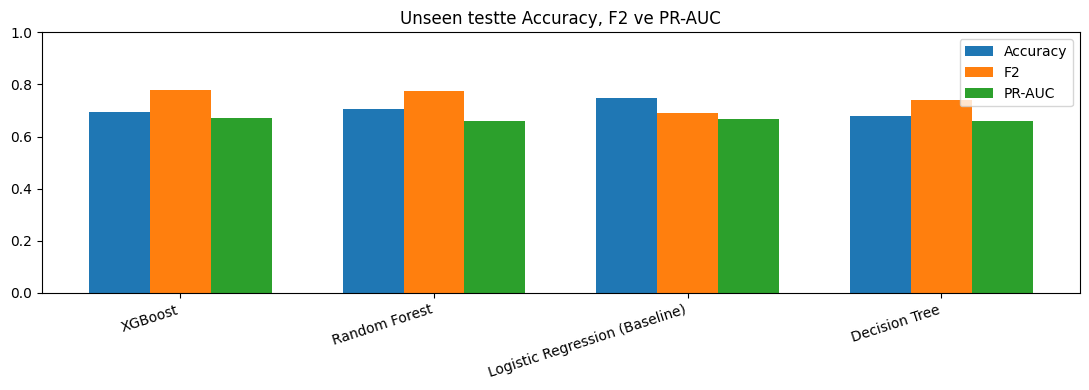

In [12]:
view=scores.loc[scores.model.ne('30 Günlük Sıklık (Kural)')]
fig,ax=plt.subplots(figsize=(11,4))
x=np.arange(len(view));w=.24
ax.bar(x-w,view.Accuracy,width=w,label='Accuracy')
ax.bar(x,view.F2,width=w,label='F2')
ax.bar(x+w,view.PR_AUC,width=w,label='PR-AUC')
ax.set_xticks(x,view.model,rotation=18,ha='right');ax.set_ylim(0,1)
ax.set_title('Unseen testte Accuracy, F2 ve PR-AUC');ax.legend();plt.tight_layout();plt.show()

## 13. Precision–Recall ve ROC eğrileri

Rastgele modelin PR-AUC referansı, ilgili testte pozitif sınıf oranıdır. ROC-AUC, doğruluk (`accuracy`) yüzdesi değildir. Accuracy karar eşiğine bağlıdır; ROC-AUC tüm eşikleri inceler.

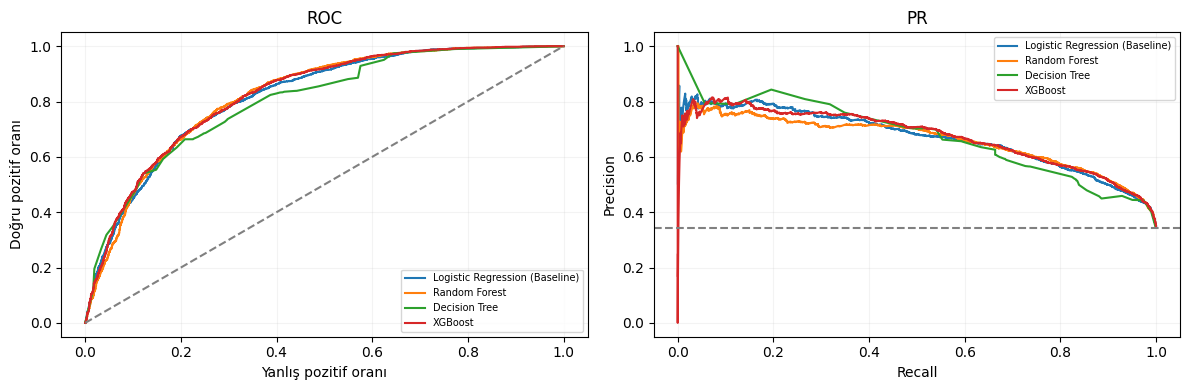

In [13]:
from sklearn.metrics import roc_curve,precision_recall_curve
from train_models import slug
pred=pd.read_csv(ROOT/'outputs'/'urun_talep_unseen_test_tahminleri.csv',parse_dates=['date'])
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name in ['Logistic Regression (Baseline)','Random Forest','Decision Tree','XGBoost']:
    col='prob_'+slug(name)
    fpr,tpr,_=roc_curve(pred.target,pred[col]);axs[0].plot(fpr,tpr,label=name)
    precision,recall,_=precision_recall_curve(pred.target,pred[col]);axs[1].plot(recall,precision,label=name)
axs[0].plot([0,1],[0,1],ls='--',color='gray');axs[1].axhline(pred.target.mean(),ls='--',color='gray')
axs[0].set(xlabel='Yanlış pozitif oranı',ylabel='Doğru pozitif oranı',title='ROC')
axs[1].set(xlabel='Recall',ylabel='Precision',title='PR')
for ax in axs:ax.legend(fontsize=7);ax.grid(alpha=.15)
plt.tight_layout();plt.show()

## 14. Testte yanlış negatifler ve yanlış pozitifler

En kritik hata türümüz **yanlış negatif**: gerçekte talep edilmesine rağmen düşük skor verilen SKU'lar. Ayrıca fazla yanlış pozitif, gereksiz depo hazırlığı yaratır. Stok tutarı bulunmadığı için parasal maliyet çıkarımı yapmıyoruz.

In [14]:
chosen=experiment['selected_model'];col='prob_'+slug(chosen)
threshold=float(scores.loc[scores.model.eq(chosen),'threshold'].iloc[0])
copy=pred.copy();copy['y_pred']=(copy[col]>=threshold).astype(int)
fn=copy[(copy.target==1)&(copy.y_pred==0)].nsmallest(10,col)
fp=copy[(copy.target==0)&(copy.y_pred==1)].nlargest(10,col)
print('Kaçırılan gerçek talep (FN):');display(fn[['date','Reference','target',col]])
print('Gereksiz hazırlık (FP):');display(fp[['date','Reference','target',col]])

Kaçırılan gerçek talep (FN):


,date,Reference,target,prob_random_forest
1651,2023-09-19,4E1WTK,1,0.008485
85,2023-09-06,F98BNI,1,0.012023
4290,2023-10-12,X0HH8Y,1,0.014050
1084,2023-09-13,CVU3QV,1,0.015849
1928,2023-09-21,GPBMZJ,1,0.017004
847,2023-09-12,6MKIC6,1,0.021892
322,2023-09-07,JWTWL1,1,0.024196
1339,2023-09-17,JHSQHS,1,0.031846
610,2023-09-08,ZVUW6Z,1,0.032765
3092,2023-10-04,4E1WTK,1,0.038207


Gereksiz hazırlık (FP):


,date,Reference,target,prob_random_forest
3733,2023-10-10,8D9SAW,0,0.930610
3793,2023-10-10,I1KDJ0,0,0.930421
2351,2023-09-26,I1KDJ0,0,0.926652
3747,2023-10-10,AKP0A7,0,0.921270
2291,2023-09-26,8D9SAW,0,0.918228
1471,2023-09-18,8N10W9,0,0.917650
2305,2023-09-26,AKP0A7,0,0.915686
1267,2023-09-17,8N10W9,0,0.915399
3814,2023-10-10,KTDZY0,0,0.913597
2898,2023-10-03,6M2FJM,0,0.912815


## 15. Kapasite sınırlı hazırlık için Top-20

`Precision@20`: O gün önerilen 20 ürün içinde gerçekten talep edilenlerin oranı. `Recall@20`: O gün gerçekten talep edilen bütün aday ürünlerin ne kadarının ilk 20 listede yakalandığı. Recall@20 düşük olabilir çünkü günlük pozitif SKU sayısı 20'den fazladır.

In [15]:
display(scores[['model','Precision_at_20','Recall_at_20','Precision_at_50','Recall_at_50']].round(3))

,model,Precision_at_20,Recall_at_20,Precision_at_50,Recall_at_50
0,XGBoost,0.781,0.222,0.711,0.492
1,Random Forest,0.777,0.210,0.713,0.506
2,Logistic Regression (Baseline),0.781,0.223,0.715,0.494
3,Decision Tree,0.750,0.198,0.677,0.472
4,30 Günlük Sıklık (Kural),0.773,0.221,0.700,0.498


## 16. Sezon özellikleri her dört modelde de var

Mevsim ve ay özellikleri **ürün kategorisi etiketleri değildir**. Model geçmiş alışkanlık ve tarihten yararlanır; bot/terlik ayrımı yapılmaz. 2023 Ocak–Ekim verisiyle 12 aylık tekrarın kanıtlandığı iddia edilemez.

In [16]:
print('Tüm modellerin ortak sezon özellikleri:',SEASON)
for name in ['Logistic Regression (Baseline)','Random Forest','Decision Tree','XGBoost']:
    b=joblib.load(ROOT/'models'/('urun_talep_'+slug(name)+'.joblib'))
    assert set(SEASON).issubset(set(b['features']))
    print(name,'toplam özelliği:',len(b['features']))

Tüm modellerin ortak sezon özellikleri: ['month', 'quarter', 'day_of_week', 'day_of_year_sin', 'day_of_year_cos', 'month_sin', 'month_cos', 'season_code', 'season_history_rate', 'season_history_count']
Logistic Regression (Baseline) toplam özelliği: 32
Random Forest toplam özelliği: 32
Decision Tree toplam özelliği: 32
XGBoost toplam özelliği: 32


## 17. Kayıtlı son güne göre tarihsel ürün tahmini

Son gün 19.10.2023 olduğundan 2026 için canlı tahmin üretilmez. Bu örnekte bir sonraki *varsayımsal* kayıt günü 20.10.2023 kabul edilmiştir.

In [17]:
bundle=joblib.load(ROOT/'models'/'urun_talep_secili_model.joblib')
next_day=pivot.index[-1]+pd.Timedelta(days=1)
x=future_features(pivot,next_day)
p=bundle['model'].predict_proba(x[bundle['features']])[:,1]
future=x[['Reference','freq_7','freq_30']].copy();future['ML_skoru']=p
future['Talep_etiketi']=(p>=bundle['threshold']).astype(int)
print('Kullanılan model:',bundle['choice'],'tarih:',next_day.date())
display(future.nlargest(20,'ML_skoru').round(3))

Kullanılan model: Random Forest tarih: 2023-10-20


,Reference,freq_7,freq_30,ML_skoru,Talep_etiketi
186,WRRW1W,1.000,0.833,0.816,1
43,8N10W9,1.000,0.867,0.808,1
154,SMMRK3,1.000,0.867,0.801,1
101,I1KDJ0,1.000,0.800,0.792,1
125,LXJQVG,0.857,0.833,0.788,1
55,AKP0A7,1.000,0.833,0.782,1
122,KTDZY0,1.000,0.833,0.780,1
41,8D9SAW,1.000,0.800,0.770,1
12,2T1DJM,1.000,0.867,0.760,1
165,TNAHD4,1.000,0.800,0.755,1


## 18. Exact TSP — ML'den ayrı rota problemi

ML bir raf ziyaret sırası oluşturmaz. `Picking_Wave` ve `Storage_Location` içinde koordinatı tanımlanmış dalgalar için daha önce kanıtlanmış `OPTIMAL` rotalar saklanır. Bu rotalar **yaklaşık koridor modeli** içindir.

In [18]:
from warehouse_core import load_project,wave_locations,parse_saved_route,route_details,solve_selected
project=load_project(ROOT)
wave=33168
route=parse_saved_route(project,wave);loc=wave_locations(project,wave)
details=route_details(route,loc,project['geometry'])
expected=float(project['waves'].loc[project['waves'].waveNumber.eq(wave),'optimal_distance'].iloc[0])
assert abs(details['distance']-expected)<.16
print('Dalga:',wave,'raf:',details['total_stops'],'toplam ürün:',details['total_units'])
print('Model mesafesi (koordinat):',details['distance'])
print('Ziyaret sırası:', ' → '.join(route))

Dalga: 33168 raf: 22 toplam ürün: 24
Model mesafesi (koordinat): 4516.0
Ziyaret sırası: I/O → J-14-21 → J-20-21 → L-17-23 → M-13-11 → L-09-21 → N-18-21 → P-22-22 → P-13-23 → P-14-12 → Q-13-22 → P-09-13 → O-13-11 → O-17-11 → O-13-12 → N-01-23 → M-04-13 → M-01-21 → M-02-21 → J-03-23 → J-09-23 → K-16-11 → K-16-12 → I/O


## 19. Yeni raf kümesi için Exact TSP

Optimizasyon çözücüsünden `OPTIMAL` alınmadan matematiksel kesin optimum iddia edilmez. Kütüphane kuruluysa OR-Tools CP-SAT, değilse aynı kesin TSP için SciPy MILP kullanılır.

In [19]:
sample=loc.head(5).copy()
answer,steps=solve_selected(project,sample,limit_sec=15,prefer_cp_sat=True)
print(answer)
print('Rota:',steps)
assert answer['status']=='OPTIMAL' 

{'status': 'OPTIMAL', 'order': [0, 1, 2, 5, 3, 4, 0], 'distance': 1316.0, 'elapsed': 0.007546815999376122, 'backend': 'SciPy MILP'}
Rota: ['I/O', 'J-03-23', 'J-09-23', 'K-16-11', 'J-14-21', 'J-20-21', 'I/O']


## 20. Hareketli forklift simülasyonu

Saklanmış optimum ziyaret sırasını, fiziksel sürüş kaydı değil, şematik bir tarayıcı animasyonu olarak canlandırırız. Streamlit `Rota & Simülasyon` sayfasında oynatılabilir.

In [20]:
from forklift_simulator import render_simulator
bg=storage.loc[pd.to_numeric(storage['z'],errors='coerce').eq(1),['x','y']].dropna().astype(float).values.tolist()
html=render_simulator(details,bg)
out=ROOT/'outputs'/'forklift_ornek_33168.html'
out.write_text(html,encoding='utf-8')
print('Forklift simülasyonu:',out,'bayt:',out.stat().st_size)
print('Web sitesinde Rota & Simülasyon menüsünden oynatılabilir.')

Forklift simülasyonu: /mnt/data/DepoNav_4_Model_XGBoost_2026_FINAL/outputs/forklift_ornek_33168.html bayt: 29861
Web sitesinde Rota & Simülasyon menüsünden oynatılabilir.


## 21. Web sitesi ve tekrar üretilebilirlik

Uygulama sayfaları: Genel Bakış, Ürün Talep Tahmini, ML Performansı, Rota & Simülasyon, Yeni Rota Planı, Veri & Metodoloji.

`python -m streamlit run app.py` ile çalıştırılır. Kaydedilmiş modellerin scikit-learn ve XGBoost sürümleri `requirements.txt` ile sabitlenmiştir. Günlük test sonuçlarına bakıp sonra modeli yeniden seçmeyiz.

In [21]:
print('Streamlit dosyası:',ROOT/'app.py')
print('Eğitim kodu:',ROOT/'train_models.py')
print('Eğitilmiş modeller:',[p.name for p in sorted((ROOT/'models').glob('*.joblib'))])
print('Unseen test çıktısı:',ROOT/'outputs'/'urun_talep_unseen_test_metrikleri.csv')

Streamlit dosyası: /mnt/data/DepoNav_4_Model_XGBoost_2026_FINAL/app.py
Eğitim kodu: /mnt/data/DepoNav_4_Model_XGBoost_2026_FINAL/train_models.py
Eğitilmiş modeller: ['urun_talep_decision_tree.joblib', 'urun_talep_logistic_regression.joblib', 'urun_talep_random_forest.joblib', 'urun_talep_secili_model.joblib', 'urun_talep_xgboost.joblib']
Unseen test çıktısı: /mnt/data/DepoNav_4_Model_XGBoost_2026_FINAL/outputs/urun_talep_unseen_test_metrikleri.csv


## 22. Akademik sonuç ve sınırlılıklar

- **Ana görev:** Geçmiş sipariş + mevsim özellikleriyle ertesi kayıtlı operasyon gününde ürünün talep edilme olasılığı.
- **Baseline:** Logistic Regression. Geliştirilen üç alternatif: Random Forest, Decision Tree ve XGBoost.
- **CV:** Zamanı koruyan 3 fold; hiperparametre ve eşik yalnız eğitim döneminde; ayrı doğrulama son model ailesini seçer.
- **Metrik kararı:** Accuracy ve Balanced Accuracy raporlanır. Hazırlıksız kalmamak için recall ağırlıklı F2; gereksiz hazırlığı sınırlamak için precision tabanı ve Precision@20 ayrıca raporlanır.
- **Bağımsız test:** Model seçimine katılmayan son 26 operasyon günü; testte precision tabanı karşılanmıyorsa açıkça raporlanır.
- **Sezon:** Ürün tipi bilinmiyor; tarih özellikleri kullanılabilir ama tek kısmi yıl, doğrulanmış sezon döngüsü değildir.
- **Optimizasyon:** Gerçekleşmiş dalgalar için Exact TSP ayrı problem; fiziksel koridor modeli henüz doğrulanmış değildir.
- **Sonraki geliştirme:** Yeni yıllar, gerçek depo geçiş geometrisi, stok verisi ve kullanılabilir hazırlık kapasitesi bilgileri.
